# P1.1 rain-only reference population and P1.2 rain-only expectation model (Ogallala)

Driver for the `paper1` package (research plan revision 2, section 5.3, updated to plan v3 cards P1.0-P1.2). The code lives in the folder `paper1`; this notebook only sets the run up, calls it, and shows what it produced.

**Before the first run**
1. Copy the repository folder `paper1` to Google Drive as `MyDrive/MSUGWB/code/paper1` (the whole folder; re-copy after every code change - outputs record a hash of the code they were made with).
2. Inputs must be on Drive where `paper1/config.py` (`DATASETS`) expects them (checked 2026-11-11): Landsat `LANDSAT_C2L2_indices_30m_monthly_tiles_v2_latest` (2015-2026 so far), OpenET `OPENET_v2_0_monthly_30m_tiles`, CDL `USDA_NASS_CDL_30m_tiles` (each with `frames.json`), the NWI tiles (made by `Colab notebooks/NWI_Wetlands_30m_Ogallala.ipynb`), `GRIDMET_LAB_NEW/GRIDMET_Ogallala_lab.nc` and `GRIDMET_DROUGHT_Ogallala_lab.nc`, the GLO-30 DEM in `MyDrive/MGU GWB datasets/merged_datasets (1)/`, `HRES_WTD/HRES_WTD_Ogallala.nc`, `LANID/...nc`, gSSURGO 120 m and GDE in `USGS data/derived_usgs/`, and `MyDrive/high_plains_quifer.zip`. NHDPlus HR, the Copernicus DEM tiles for HAND and the Census counties are downloaded by the pipeline.
3. Use a GPU runtime for P1.2 (Runtime > Change runtime type). P1.1 runs on CPU. P1.2 needs `calendars.season_window` written first.

**Order:** `RUN_MODE = "test"` first (minutes; a 30 km window of one tile, 2015-2016), read the reports, then `"focus"` (focus-landscape tiles) or `"full"`. In `focus`/`full` mode a failed gate (G1a, G1b) halts the stages after it unless listed in `GATE_OVERRIDE`.

**Monitoring:** cell 9 prints the stage table at any time; the log is `<outputs>/logs/run_<date>.log`, one line per unit of work in `<outputs>/ledger.jsonl`. A stage that hits the session time budget stops cleanly - rerun the same cell in a new session and it continues. See `paper1/docs/MONITORING.md`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# ═══════════════ CELL 1: settings (edit these, then Run all) ═══════════════
RUN_MODE = "full"            # "test" | "focus" | "full"
WHAT = ["p11"]               # "p11" (Step 0 + P1.1), "p12" (P1.2), "all", or stage names e.g. ["tiles", "blocks"]
FORCE = False                # True recomputes the named stages even if complete (rarely needed: settings changes get new folders)
CODE_ON_DRIVE = "/content/drive/MyDrive/MSUGWB/code/paper1"
STOP_ON_PREFLIGHT_PROBLEMS = True
RUN_TESTS = True             # unit tests before, provenance tests after the run

In [3]:
# ═══════════════ CELL 2: install ═══════════════
!pip install -q "pysheds==0.5" netCDF4 rasterio pyogrio 2>&1 | tail -2

In [4]:
# ═══════════════ CELL 3: mount Drive, load the code ═══════════════
import os, sys, shutil, hashlib, json
if not os.path.ismount('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(CODE_ON_DRIVE), f"copy the paper1 folder to {CODE_ON_DRIVE} first"
LOCAL_CODE = "/content/code/paper1"
shutil.rmtree(LOCAL_CODE, ignore_errors=True)
shutil.copytree(CODE_ON_DRIVE, LOCAL_CODE, ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
os.environ["P1_RUN_ENV"], os.environ["P1_RUN_MODE"] = "colab", RUN_MODE
if "/content/code" not in sys.path:
    sys.path.insert(0, "/content/code")
for m in [m for m in sys.modules if m == "paper1" or m.startswith("paper1.")]:
    del sys.modules[m]                       # pick up a re-copied folder without restarting the runtime
import paper1.config as C
C.RUN_ENV, C.RUN_MODE = "colab", RUN_MODE
h = hashlib.md5()
for root, _, files in sorted(os.walk(LOCAL_CODE)):
    for f in sorted(files):
        if f.endswith(".py"):
            h.update(open(os.path.join(root, f), "rb").read())
print("paper1 code md5:", h.hexdigest()[:12], "| outputs:", C.out_root())

paper1 code md5: 4e50ec6ffca1 | outputs: /content/drive/MyDrive/MSUGWB/P1_rain_only


In [5]:
# ═══════════════ CELL 4: preflight (inputs, sizes, libraries, GPU, Drive read speed) ═══════════════
from paper1.__main__ import preflight
rep = preflight()
print(json.dumps({k: rep.get(k) for k in ("run_mode", "tiles", "tile_files", "read_mb_per_s", "scratch_free_gb", "gpu", "libraries")}, indent=1, default=str))
for n in rep.get("notes", []):
    print("NOTE:", n)
for p in rep["problems"]:
    print("PROBLEM:", p)
if rep["problems"] and STOP_ON_PREFLIGHT_PROBLEMS:
    raise SystemExit("preflight found problems (listed above); fix them or set STOP_ON_PREFLIGHT_PROBLEMS = False")

{
 "run_mode": "full",
 "tiles": [
  "z13e02n30",
  "z13e03n23",
  "z13e03n24",
  "z13e03n25",
  "z13e03n26",
  "z13e03n28",
  "z13e03n29",
  "z13e03n30",
  "z13e03n31",
  "z13e04n22",
  "z13e04n23",
  "z13e04n24",
  "z13e04n25",
  "z13e04n26",
  "z13e04n27",
  "z13e04n28",
  "z13e04n29",
  "z13e04n30",
  "z13e04n31",
  "z13e05n22",
  "z13e05n23",
  "z13e05n24",
  "z13e05n25",
  "z13e05n26",
  "z13e05n27",
  "z13e05n28",
  "z13e05n29",
  "z13e05n30",
  "z13e05n31",
  "z14e00n23",
  "z14e00n24",
  "z14e00n25",
  "z14e00n26",
  "z14e00n27",
  "z14e00n28",
  "z14e00n30",
  "z14e00n31",
  "z14e01n22",
  "z14e01n23",
  "z14e01n24",
  "z14e01n25",
  "z14e01n26",
  "z14e01n27",
  "z14e01n28",
  "z14e01n29",
  "z14e01n30",
  "z14e01n31",
  "z14e02n24",
  "z14e02n25",
  "z14e02n26",
  "z14e02n27",
  "z14e02n28",
  "z14e02n29",
  "z14e02n30",
  "z14e02n31",
  "z14e03n25",
  "z14e03n26",
  "z14e03n27",
  "z14e03n28",
  "z14e03n29",
  "z14e03n30",
  "z14e03n31",
  "z14e04n26",
  "z14e04n27",
  "z1

SystemExit: preflight found problems (listed above); fix them or set STOP_ON_PREFLIGHT_PROBLEMS = False

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
# ═══════════════ CELL 5: unit tests (seconds) ═══════════════
if RUN_TESTS:
    !cd /content/code && P1_RUN_ENV=colab P1_RUN_MODE={RUN_MODE} python -m paper1 test unit

-- test_unit_core
   skip  test_vendored_copies_agree_with_residual_et  residual_et not importable (ModuleNotFoundError)
   ok    test_fingerprint_identity_ignores_mtime_but_not_content  (0.2s)
   ok    test_signature_follows_config_and_upstream  (0.0s)
   ok    test_write_nc_reads_back_and_marks_complete  (0.3s)
   ok    test_read_window_pads_outside_the_file  (0.0s)
   ok    test_config_snapshot_is_json_and_check_refuses_bad_modes  (0.0s)
   ok    test_oracle_is_independent_of_the_pipeline  (0.0s)
   ok    test_config_md_is_current  (0.1s)
17:07:54 | WARNING | paper1 | gate G1a (a) does not pass - overridden by GATE_OVERRIDE, b runs: V2 fails
17:07:54 | WARNING | paper1 | gate G1a (a) does not pass - test mode, b runs anyway: V2 fails
   ok    test_a_failed_gate_halts_dependents_in_full_mode_unless_overridden  (0.0s)
-- test_unit_step0
   ok    test_frame_offsets_and_block_window  (0.0s)
   ok    test_frame_off_lattice_is_refused  (0.0s)
   ok    test_block_stats_equal_brute_force  (

In [ ]:
# ═══════════════ CELL 6: run ═══════════════
from paper1.pipeline import runner, P11, P12
from paper1.__main__ import print_status
expand = dict(p11=P11, p12=P12, all=P11 + P12)
targets = [s for n in WHAT for s in expand.get(n, [n])]
try:
    runner().run(targets, force=FORCE)
finally:
    print_status()

17:08:05 | INFO    | paper1 | stage tiles        1686d11e  complete - skipped
17:08:05 | INFO    | paper1 | stage blocks       3dfd1f88  complete - skipped
17:08:05 | INFO    | paper1 | stage drivers      f2b674ff  complete - skipped
17:08:05 | INFO    | paper1 | stage counties     9bcb0540  complete - skipped


17:08:05 | INFO    | paper1 | stage hand         fb84b9d7  running -> /content/drive/MyDrive/MSUGWB/P1_rain_only/_test/hand/fb84b9d7
17:08:11 | INFO    | paper1.hand | NHDPlus HR HU4s for (-100.56313047391525, 40.783188697333685, -100.19263595866042, 41.064201795130025): ['1020', '1021', '1025']
17:16:03 | INFO    | paper1.hand | HU8 10200101: 11988965 cells, 2.9 % without HAND
17:17:15 | INFO    | paper1.hand | HU8 10250008: 3316462 cells, 1.7 % without HAND
17:17:19 | INFO    | paper1.hand | downloaded https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_N38_00_W102_00_DEM/Copernicus_DSM_COG_10_N38_00_W102_00_DEM.tif (35.4 MB)
17:17:24 | INFO    | paper1.hand | downloaded https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_N38_00_W101_00_DEM/Copernicus_DSM_COG_10_N38_00_W101_00_DEM.tif (37.6 MB)
17:17:28 | INFO    | paper1.hand | downloaded https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_N38_00_W100_00_DEM/Copernicus_DSM_COG_10_N38_00_W100

RUN_ENV=colab RUN_MODE=test outputs: /content/drive/MyDrive/MSUGWB/P1_rain_only/_test
stage        signature complete  units  last error / summary
tiles        1686d11e  True          1  {"tiles": 1, "blocks": 4096, "valid_blocks": 4096, "primary_valid": 4096, "frames": {"openet": "identical", "c
blocks       3dfd1f88  True          2  {"written": 2, "already_complete": 0, "missing": []}
drivers      f2b674ff  True          0  {"cells": 29125, "months": 261, "first": "2005-01-01", "last": "2026-09-01", "aridity_edges": [0.2509939610958
counties     9bcb0540  True          0  {"counties": 715, "source": {"url": "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip
hand         fb84b9d7  True          6  {"hu4": ["1020", "1021", "1025"], "hu8": 3, "computed_now": 3}
             older outputs with other settings/code: e2622b94
static       13769fb3  True          1  {"tiles": 1}
classes      cbdff3cb  True          2  {"missing": []}
dryland      ac6be4f6  True      

In [ ]:
# ═══════════════ CELL 7: provenance tests on what was just produced ═══════════════
if RUN_TESTS:
    !cd /content/code && P1_RUN_ENV=colab P1_RUN_MODE={RUN_MODE} python -m paper1 test provenance

-- test_provenance
   ok    test_sources_are_the_expected_files  (1.3s)
   ok    test_refused_files_are_refused  (0.0s)
   ok    test_outputs_cite_inputs_that_match_the_files_here  (3.1s)
   ok    test_block_statistics_trace_to_the_tile_files  (3.2s)
   ok    test_monthly_drivers_trace_to_daily_gridmet  (11.8s)
   ok    test_static_layers_trace_to_their_sources  (4.5s)
   ok    test_class_counts_trace_to_cdl  (1.4s)
   ok    test_hand_follows_the_stored_d8_directions  (68.8s)
   ok    test_reference_flags_recompute_from_block_statistics  (0.1s)
   skip  test_training_samples_are_reference_blocks  stage(s) ['samples'] not complete for RUN_ENV=colab RUN_MODE=test under /content/drive/MyDrive/MSUGWB/P1_rain_only/_test
   ok    test_rebuilding_a_tile_year_gives_identical_arrays  (7.7s)
   ok    test_a_wrong_scale_factor_is_caught  (0.1s)
11 passed, 0 failed, 1 skipped


# P1.1 verification

**Gate G1a: FAIL** - V2: 26.0 % of reference block-years within the water bound (needed 95 %); see the V2 diagnosis; V1: no functional group x decile stratum has 500 reference blocks

Not assessed: Kansas registry comparison (WIMAS not on disk); ring test (needs the P1.2 models: reported by verify_p12); NWI rule: no NWI tile for z14e02n29 - the rule passed every block there

## reference

V1: 282 distinct reference blocks; 0 strata (aridity decile x functional group) with >= 500 blocks; 2 out of domain.

| decile | functional group | distinct blocks | block-years |
|---|---|---|---|
| 7 | perennial_grass | 8 | 15 |
| 8 | perennial_grass | 274 | 534 |

V2: 72 of 277 reference block-years (26.0 %) have water-year ET <= (P - dS) x 1.10; needed 95 %: **FAIL**. ET / (P - dS) quantiles 5/50/95 %: 1.00, 1.17, 1.34

V2 diagnosis: no concentration near irrigation: if V2 fails, suspect the ET or rain product (compare with rain-fed flux towers)

| distance to LANID | block-years | failure rate |
|---|---|---|
| 800-1600 m | 46 | 56.5 % |
| 1600-3200 m | 73 | 75.3 % |
| 3200-inf m | 158 | 78.5 % |

V4 representativeness (|SMD| <= 0.25): **FAIL**; beyond the limit: 7|rootznaws, 7|elevation, 8|aws0_150, 8|rootznaws, 8|nccpi3all, 8|elevation, 8|P_annual, 8|PET_annual. Not available: clay, slope.

## reference_gde

V1: 282 distinct reference blocks; 0 strata (aridity decile x functional group) with >= 500 blocks; 2 out of domain.

| decile | functional group | distinct blocks | block-years |
|---|---|---|---|
| 7 | perennial_grass | 8 | 15 |
| 8 | perennial_grass | 274 | 534 |

V2: 72 of 277 reference block-years (26.0 %) have water-year ET <= (P - dS) x 1.10; needed 95 %: **FAIL**. ET / (P - dS) quantiles 5/50/95 %: 1.00, 1.17, 1.34

V2 diagnosis: no concentration near irrigation: if V2 fails, suspect the ET or rain product (compare with rain-fed flux towers)

| distance to LANID | block-years | failure rate |
|---|---|---|
| 800-1600 m | 46 | 56.5 % |
| 1600-3200 m | 73 | 75.3 % |
| 3200-inf m | 158 | 78.5 % |

V4 representativeness (|SMD| <= 0.25): **FAIL**; beyond the limit: 7|rootznaws, 7|elevation, 8|aws0_150, 8|rootznaws, 8|nccpi3all, 8|elevation, 8|P_annual, 8|PET_annual. Not available: clay, slope.

## reference_irr3

V1: 283 distinct reference blocks; 0 strata (aridity decile x functional group) with >= 500 blocks; 2 out of domain.

| decile | functional group | distinct blocks | block-years |
|---|---|---|---|
| 7 | perennial_grass | 9 | 17 |
| 8 | perennial_grass | 274 | 534 |

V2: 73 of 278 reference block-years (26.3 %) have water-year ET <= (P - dS) x 1.10; needed 95 %: **FAIL**. ET / (P - dS) quantiles 5/50/95 %: 1.00, 1.17, 1.34

V2 diagnosis: no concentration near irrigation: if V2 fails, suspect the ET or rain product (compare with rain-fed flux towers)

| distance to LANID | block-years | failure rate |
|---|---|---|
| 0-800 m | 1 | 0.0 % |
| 800-1600 m | 46 | 56.5 % |
| 1600-3200 m | 73 | 75.3 % |
| 3200-inf m | 158 | 78.5 % |

V4 representativeness (|SMD| <= 0.25): **FAIL**; beyond the limit: 7|aws0_150, 7|rootznaws, 7|elevation, 8|aws0_150, 8|rootznaws, 8|nccpi3all, 8|elevation, 8|P_annual, 8|PET_annual. Not available: clay, slope.

## Ring (blocks only the class rung admits)

8|perennial_grass: 274

## P1.0 valid share, April-September

2012 is not among the processed years: not assessed.

V3 maps: reference_2015.png, reference_2016.png


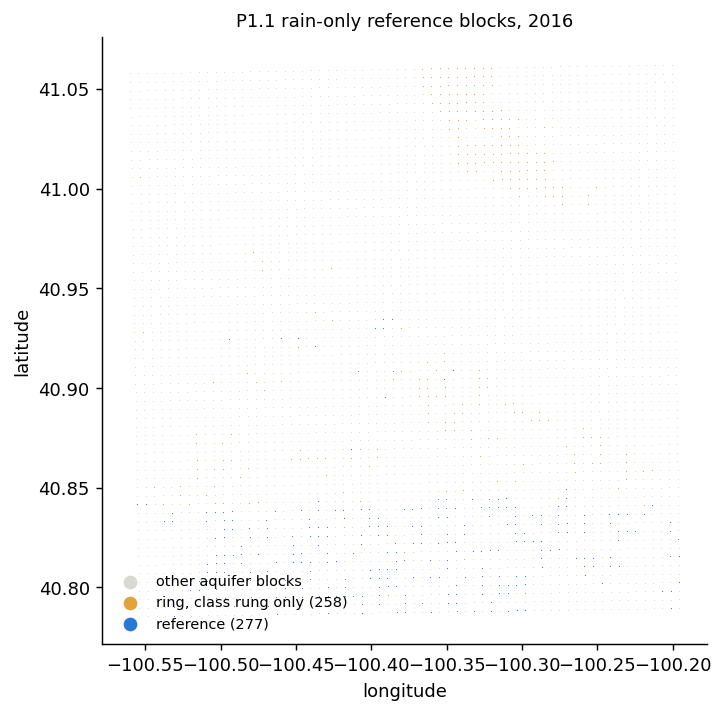

verify_p12: not complete for RUN_MODE=test


In [ ]:
# ═══════════════ CELL 8: reports ═══════════════
from IPython.display import Markdown, Image, display
from paper1.tests.util import stage_dir
for st, name in (("verify_p11", "verify_p11.md"), ("verify_p12", "verify_p12.md")):
    d = stage_dir(st)
    if d:
        display(Markdown(open(f"{d}/reports/{name}").read()))
        pngs = sorted(f for f in os.listdir(f"{d}/reports") if f.endswith(".png"))
        if pngs:
            display(Image(f"{d}/reports/{pngs[-1]}", width=520))
    else:
        print(f"{st}: not complete for RUN_MODE={RUN_MODE}")

In [ ]:
# ═══════════════ CELL 9: status (run any time) ═══════════════
from paper1.__main__ import print_status
print_status()
!tail -n 15 "{C.out_root()}/logs/"*.log

RUN_ENV=colab RUN_MODE=test outputs: /content/drive/MyDrive/MSUGWB/P1_rain_only/_test
stage        signature complete  units  last error / summary
tiles        1686d11e  True          1  {"tiles": 1, "blocks": 4096, "valid_blocks": 4096, "primary_valid": 4096, "frames": {"openet": "identical", "c
blocks       3dfd1f88  True          2  {"written": 2, "already_complete": 0, "missing": []}
drivers      f2b674ff  True          0  {"cells": 29125, "months": 261, "first": "2005-01-01", "last": "2026-09-01", "aridity_edges": [0.2509939610958
counties     9bcb0540  True          0  {"counties": 715, "source": {"url": "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip
hand         fb84b9d7  True          6  {"hu4": ["1020", "1021", "1025"], "hu8": 3, "computed_now": 3}
             older outputs with other settings/code: e2622b94
static       13769fb3  True          1  {"tiles": 1}
classes      cbdff3cb  True          2  {"missing": []}
dryland      ac6be4f6  True      

In [ ]:
# ═══════════════ CELL 10: reading the outputs (example) ═══════════════
# import xarray as xr
# ref = xr.open_dataset(f"{stage_dir('reference')}/z14e02n29/P1_reference_z14e02n29.nc")       # P1.1, (year, by, bx)
# exp = xr.open_dataset(f"{stage_dir('predict')}/2015/z14e02n29/P1_expectation_z14e02n29_2015.nc")  # P1.2, (month, by, bx)
# exp["ET_q50"].isel(month=6).plot()